## Project Overview

#### This is my first machine learning project, created to better understand how linear regression works in practice. The data was collected by scraping polovniautomobili.com, the largest used-car marketplace in Serbia (the scraping and data collection process was done in a separate notebook). Around 1700 listings were collected, with features such as age, mileage, engine power, engine size, fuel type, transmission, and body type.

#### As mentioned, the goal was not to build a perfect model, but to better understand how things work in practice. This notebook walks through the full process: data cleaning and outlier detection, exploratory data analysis (correlations, distributions), building a baseline linear regression model, identifying its shortcomings (heteroscedasticity, impossible negative predictions), and iteratively improving the model through a logarithmic transformation of the price, Ridge regression, and outlier removal — with a critical evaluation of whether each step actually led to improvement.

### Column reference

| Column | English | Description |
|---|---|---|
| `cena` | price | Car price (€) |
| `starost` | age | Car age (years) |
| `karoserija` | body type | Body type (sedan, hatchback, SUV...) |
| `kubikaza` | engine size | Engine displacement (cm³) |
| `gorivo` | fuel type | Fuel type (petrol, diesel, hybrid...) |
| `kilometraza` | mileage | Mileage driven (km) |
| `snaga_kw` | power (kW) | Engine power in kilowatts |
| `snaga_ks` | power (HP) | Engine power in horsepower |
| `menjac` | transmission | Transmission type (manual/automatic) |
| `broj_vrata` | number of doors | Number of doors |
| `broj_sedista` | number of seats | Number of seats |

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv('cars.csv')
df.head()

,Unnamed: 0,cena,starost,karoserija,kubikaza,gorivo,kilometraza,snaga_kw,snaga_ks,menjac,broj_vrata,broj_sedista
0,0,8600,15,Hečbek,1390,Benzin,180186,136,185,Automatski/Poluautomatski,3,4
1,1,5490,15,Hečbek,1197,Benzin,198447,77,105,Manuelni,5,5
2,2,12700,14,Džip/SUV,1968,Dizel,212000,103,140,Manuelni,5,5
3,3,8600,13,Hečbek,1497,Hibridni pogon (benzin),179482,74,101,Automatski/Poluautomatski,5,5
4,4,6299,17,Kupe,1390,Benzin,202000,118,160,Manuelni,3,4


In [3]:
df.drop('Unnamed: 0',axis=1,inplace=True)

## original dataset

In [4]:
df.head()

,cena,starost,karoserija,kubikaza,gorivo,kilometraza,snaga_kw,snaga_ks,menjac,broj_vrata,broj_sedista
0,8600,15,Hečbek,1390,Benzin,180186,136,185,Automatski/Poluautomatski,3,4
1,5490,15,Hečbek,1197,Benzin,198447,77,105,Manuelni,5,5
2,12700,14,Džip/SUV,1968,Dizel,212000,103,140,Manuelni,5,5
3,8600,13,Hečbek,1497,Hibridni pogon (benzin),179482,74,101,Automatski/Poluautomatski,5,5
4,6299,17,Kupe,1390,Benzin,202000,118,160,Manuelni,3,4


In [5]:
print(df.isnull().sum())
print()
print(df.dtypes)

cena            0
starost         0
karoserija      0
kubikaza        0
gorivo          0
kilometraza     0
snaga_kw        0
snaga_ks        0
menjac          0
broj_vrata      0
broj_sedista    0
dtype: int64

cena             int64
starost          int64
karoserija      object
kubikaza         int64
gorivo          object
kilometraza      int64
snaga_kw         int64
snaga_ks         int64
menjac          object
broj_vrata       int64
broj_sedista     int64
dtype: object


## There are no null values in the dataset because I handled them while scraping the data.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1710 entries, 0 to 1709
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   cena          1710 non-null   int64 
 1   starost       1710 non-null   int64 
 2   karoserija    1710 non-null   object
 3   kubikaza      1710 non-null   int64 
 4   gorivo        1710 non-null   object
 5   kilometraza   1710 non-null   int64 
 6   snaga_kw      1710 non-null   int64 
 7   snaga_ks      1710 non-null   int64 
 8   menjac        1710 non-null   object
 9   broj_vrata    1710 non-null   int64 
 10  broj_sedista  1710 non-null   int64 
dtypes: int64(8), object(3)
memory usage: 147.1+ KB


In [7]:
df.describe(include='all')

,cena,starost,karoserija,kubikaza,gorivo,kilometraza,snaga_kw,snaga_ks,menjac,broj_vrata,broj_sedista
count,1710.000000,1710.000000,1710,1710.000000,1710,1.710000e+03,1710.000000,1710.000000,1710,1710.000000,1710.000000
unique,NaN,NaN,8,NaN,7,NaN,NaN,NaN,2,NaN,NaN
top,NaN,NaN,Hečbek,NaN,Dizel,NaN,NaN,NaN,Manuelni,NaN,NaN
freq,NaN,NaN,637,NaN,1101,NaN,NaN,NaN,1271,NaN,NaN
mean,7566.858480,16.064327,NaN,1739.387719,NaN,2.263706e+05,93.495906,127.223977,NaN,4.770760,4.965497
std,8740.742205,6.467044,NaN,467.830632,NaN,1.091411e+05,39.274234,53.379314,NaN,0.637312,0.492759
min,100.000000,0.000000,NaN,110.000000,NaN,0.000000e+00,24.000000,33.000000,NaN,3.000000,2.000000
25%,2400.000000,11.000000,NaN,1405.500000,NaN,1.850000e+05,66.000000,90.000000,NaN,5.000000,5.000000
50%,4875.000000,16.000000,NaN,1686.000000,NaN,2.222220e+05,85.000000,116.000000,NaN,5.000000,5.000000
75%,9497.500000,20.000000,NaN,1984.000000,NaN,2.688390e+05,110.000000,150.000000,NaN,5.000000,5.000000


In [8]:
print(df['menjac'].value_counts())
print(df['karoserija'].value_counts())

menjac
Manuelni                     1271
Automatski/Poluautomatski     439
Name: count, dtype: int64
karoserija
Hečbek                637
Limuzina              331
Džip/SUV              316
Karavan               233
Monovolumen           126
Kupe                   48
Pickup                 11
Kabriolet/Roadster      8
Name: count, dtype: int64


### Due to the small number of pickup and cabriolet vehicles, they will be grouped together into the category 'other

In [9]:

df.loc[df['karoserija'].isin(['Pickup','Kabriolet/Roadster']),'karoserija']='ostalo'

In [10]:
print(df['karoserija'].value_counts())

karoserija
Hečbek         637
Limuzina       331
Džip/SUV       316
Karavan        233
Monovolumen    126
Kupe            48
ostalo          19
Name: count, dtype: int64


In [11]:
print(df['gorivo'].value_counts())

gorivo
Dizel                      1101
Benzin                      482
Benzin + Gas (TNG)           75
Benzin + Metan (CNG)         24
Hibridni pogon (benzin)      16
Hibridni pogon (dizel)        9
Plug-in hibrid                3
Name: count, dtype: int64


### Due to the small number of samples, the last three categories will be grouped into the category 'Hybrid'

In [12]:

df.loc[df['gorivo'].isin(['Plug-in hibrid','Hibridni pogon (benzin)','Hibridni pogon (dizel)']),'gorivo']='Hibrid'

In [13]:
print(df['gorivo'].value_counts())

gorivo
Dizel                   1101
Benzin                   482
Benzin + Gas (TNG)        75
Hibrid                    28
Benzin + Metan (CNG)      24
Name: count, dtype: int64


In [14]:
import seaborn as sns

## Outlier check

<Axes: ylabel='cena'>

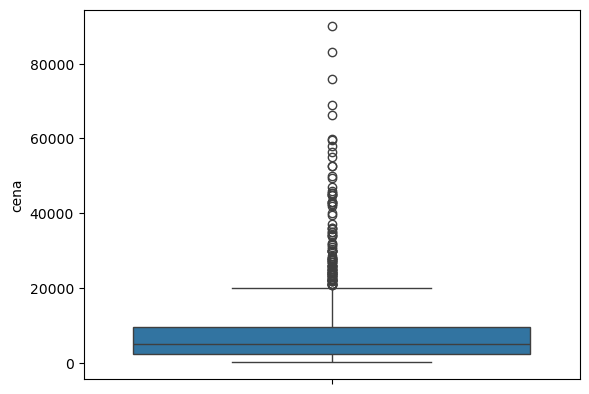

In [15]:
sns.boxplot(df['cena'])

In [16]:
df[df['cena'] >65000][['cena', 'karoserija', 'kubikaza', 'starost']]


,cena,karoserija,kubikaza,starost
50,89990,Džip/SUV,3996,6
687,66400,Limuzina,1968,1
745,69000,Limuzina,1968,0
1128,75990,Džip/SUV,1995,0
1643,83000,Džip/SUV,2998,3


### The upper outliers appear to be real data

In [17]:
df[df['cena'] <500][['cena', 'karoserija', 'kubikaza', 'starost']]


,cena,karoserija,kubikaza,starost
234,300,Hečbek,1100,38
246,300,Hečbek,1396,31
289,300,Hečbek,1300,37
305,350,Hečbek,1890,23
379,400,Limuzina,2000,26
418,250,Hečbek,1910,23
421,100,Karavan,1598,26
496,350,Limuzina,1400,25
605,450,Karavan,1997,24
628,170,Hečbek,796,24


#### The lower outliers also appear fine, except for the car at index 1064, which stands out due to its engine size of 110

In [18]:
df.loc[1064]

cena                 450
starost               31
karoserija      Limuzina
kubikaza             110
gorivo            Benzin
kilometraza         4900
snaga_kw              44
snaga_ks              60
menjac          Manuelni
broj_vrata             5
broj_sedista           5
Name: 1064, dtype: object

In [19]:
df[df['kubikaza'] < 600]

,cena,starost,karoserija,kubikaza,gorivo,kilometraza,snaga_kw,snaga_ks,menjac,broj_vrata,broj_sedista
669,700,22,Karavan,200,Dizel,285697,100,136,Manuelni,5,5
1064,450,31,Limuzina,110,Benzin,4900,44,60,Manuelni,5,5


#### It turns out there are two cars with an extremely small engine size, which is likely a data entry error, so both records will be removed.

In [20]:

df=df[df['kubikaza']>=600]

<Axes: ylabel='kilometraza'>

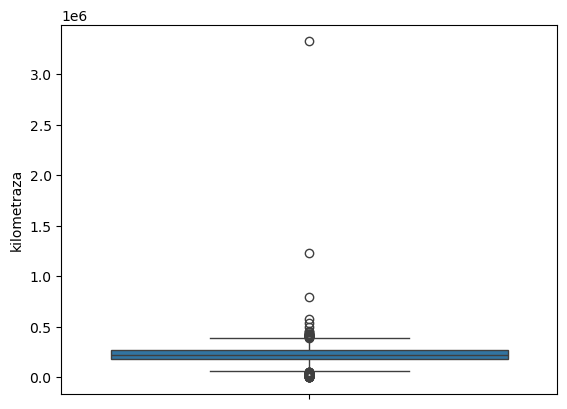

In [21]:
sns.boxplot(df['kilometraza'])

In [22]:
df[df['kilometraza'] < 100]


,cena,starost,karoserija,kubikaza,gorivo,kilometraza,snaga_kw,snaga_ks,menjac,broj_vrata,broj_sedista
64,35990,0,Džip/SUV,1498,Hibrid,0,160,218,Automatski/Poluautomatski,5,5
70,35990,0,Džip/SUV,1498,Hibrid,0,160,218,Automatski/Poluautomatski,5,5
1128,75990,0,Džip/SUV,1995,Dizel,2,140,190,Automatski/Poluautomatski,5,5


#### The lower outliers are fine, likely new cars

In [23]:
df[df['kilometraza'] > 2000000]


,cena,starost,karoserija,kubikaza,gorivo,kilometraza,snaga_kw,snaga_ks,menjac,broj_vrata,broj_sedista
1417,750,22,Hečbek,1598,Benzin,3326889,83,113,Manuelni,5,5


#### This appears unrealistic and looks like an extreme outlier, so it will be removed

In [24]:
df=df[df['kilometraza'] <= 2000000]

<Axes: ylabel='snaga_kw'>

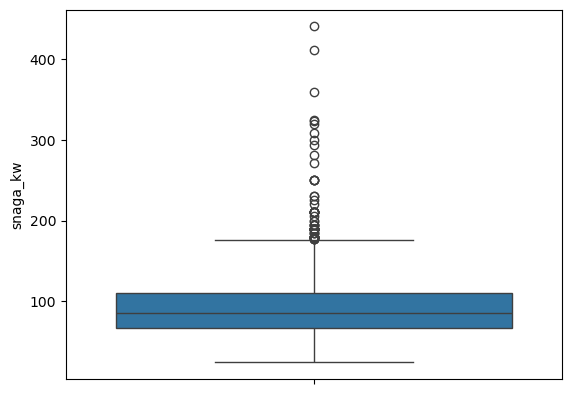

In [25]:
sns.boxplot(df['snaga_kw'])

In [26]:
outkw=df[df['snaga_kw']>300]

<Axes: ylabel='snaga_ks'>

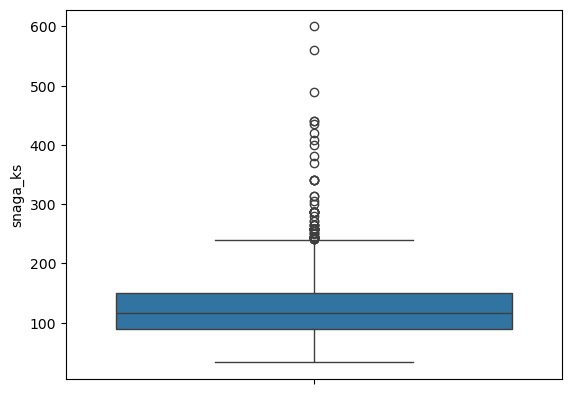

In [27]:
sns.boxplot(df['snaga_ks'])

In [28]:
outks=df[df['snaga_ks']>410]

In [29]:
print(set(outkw.index))
print(set(outks.index))


{1696, 648, 1643, 1357, 50, 627, 346}
{1696, 648, 1643, 1357, 50, 627, 346}


#### We can see that these are the same cars with high power expressed in both kW and HP, which seems fine; however, during model development we will determine whether we have a sufficient sample size for that group

In [30]:
df.corr(numeric_only=True)['cena'].sort_values(ascending=False)


cena            1.000000
snaga_ks        0.697640
snaga_kw        0.697607
kubikaza        0.416319
broj_vrata      0.153095
broj_sedista    0.019011
kilometraza    -0.311016
starost        -0.632995
Name: cena, dtype: float64

##### Power (expressed in both HP and kW) has the greatest influence on price, with an almost identical correlation coefficient for both, so during model development we will determine whether it is necessary to include both in the model. This is a positive correlation. Age also has a significant influence, with a negative correlation. The number of doors and seats has the smallest influence, so we will determine during development whether they need to be included in the model.

In [31]:
df=pd.get_dummies(df, columns=['gorivo', 'karoserija', 'menjac'], drop_first=True)


##### Categorical columns were encoded using one-hot encoding so they can be used in the model.

In [32]:
import numpy as np

## transformed dataset

In [33]:
df.head()

,cena,starost,kubikaza,kilometraza,snaga_kw,snaga_ks,broj_vrata,broj_sedista,gorivo_Benzin + Gas (TNG),gorivo_Benzin + Metan (CNG),gorivo_Dizel,gorivo_Hibrid,karoserija_Hečbek,karoserija_Karavan,karoserija_Kupe,karoserija_Limuzina,karoserija_Monovolumen,karoserija_ostalo,menjac_Manuelni
0,8600,15,1390,180186,136,185,3,4,False,False,False,False,True,False,False,False,False,False,False
1,5490,15,1197,198447,77,105,5,5,False,False,False,False,True,False,False,False,False,False,True
2,12700,14,1968,212000,103,140,5,5,False,False,True,False,False,False,False,False,False,False,True
3,8600,13,1497,179482,74,101,5,5,False,False,False,True,True,False,False,False,False,False,False
4,6299,17,1390,202000,118,160,3,4,False,False,False,False,False,False,True,False,False,False,True


## Development of a linear regression model that uses the raw 'cena' column as the target variable and all other columns as independent variables.

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
x_data=df.drop('cena',axis=1)
y_data=df['cena']
x_train,x_test,y_train,y_test=train_test_split(x_data,y_data,test_size=.3,random_state=42)
lre=LinearRegression()
lre.fit(x_train,y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [90]:
from sklearn.metrics import mean_squared_error as mse
print(f'r2 trening: {lre.score(x_train,y_train)}')
print(f'r2 test: {lre.score(x_test,y_test)}')
print(f'mse: {mse(y_test,lre.predict(x_test))}')
print(f'rmse: {np.sqrt(mse(y_test,lre.predict(x_test)))}')
print(f'mape: {np.mean(np.abs((y_test - lre.predict(x_test)) / y_test)) * 100}%')

r2 trening: 0.7187567544930087
r2 test: 0.7557126098386894
mse: 15483930.968247809
rmse: 3934.962638735952
mape: 99.38889061471326%


### Overall, the model performs relatively well, explaining around 72–76% of the variation in car prices. The similar training and test R² scores suggest that the model generalizes well and does not suffer from overfitting. However, the RMSE of approximately 3,935 indicates that there is still room for improvement in the accuracy of price predictions.

### The plot clearly shows heteroscedasticity, characterized by a distinct funnel-shaped pattern. The dispersion (variance) of the residuals increases as the predicted price rises, indicating that the model is more accurate for lower-priced vehicles but becomes significantly less precise for higher-priced ones.

<Axes: ylabel='cena'>

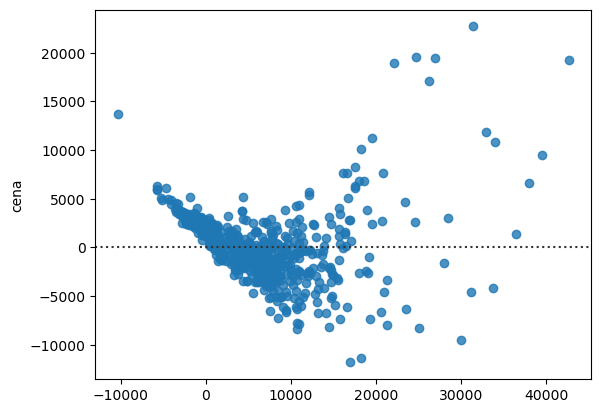

In [36]:
sns.residplot(x=lre.predict(x_test), y=y_test)


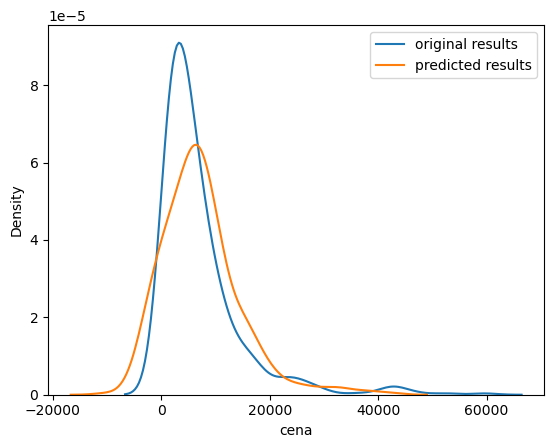

In [65]:
sns.kdeplot(y_test,label='original results')
sns.kdeplot(lre.predict(x_test),label='predicted results')
plt.legend()

### Comparing the distribution of actual prices and predicted results reveals clear discrepancies. The model fails to capture the true peak density of the actual prices, underestimating the concentration of lower to mid range values. Also, the predicted distribution extends into negative values on the left tail, which is impossible for vehicle pricing. To resolve these issues and stabilize the target distribution, a logarithmic transformation of the price will be applied.

In [37]:
y_data_log = np.log(df['cena'])
x_train, x_test, y_train_log, y_test_log = train_test_split(x_data, y_data_log, test_size=.3, random_state=42)

In [91]:
lre_log=LinearRegression()
lre_log.fit(x_train,y_train_log)
print(lre_log.score(x_train,y_train_log))
print(lre_log.score(x_test,y_test_log))
y_pred_original = np.exp(lre_log.predict(x_test))
print(f'mse: {mse(y_test, y_pred_original)}')
print(f'rmse: {np.sqrt(mse(y_test, y_pred_original))}')
print(f'mape: {np.mean(np.abs((y_test - y_pred_original) / y_test)) * 100}%')

0.791689350475172
0.8147022888879929
mse: 23276757.32671463
rmse: 4824.599188193215
mape: 36.371266869432404%


#### R-squared score has improved, meaning that a larger portion of the variance is now explained by the model. However, we can also see that the mean squared error has increased, which is not a good sign.

#### Although RMSE increased, MAPE dropped significantly, showing that the log-transformed model is actually far more accurate in relative (percentage) terms across the price range.

<Axes: ylabel='cena'>

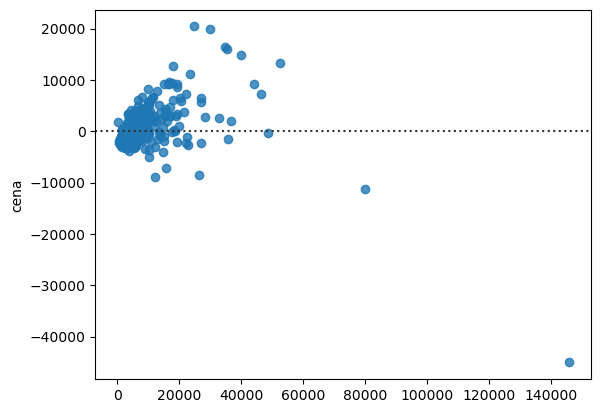

In [39]:
sns.residplot(x=np.exp(lre_log.predict(x_test)), y=np.exp(y_test_log))

### On the plot we can see that the residual situation is somewhat better. There is still some dispersion as the price increases, but the assumption is that this happens because the model lacks sufficient data for higher price cases.

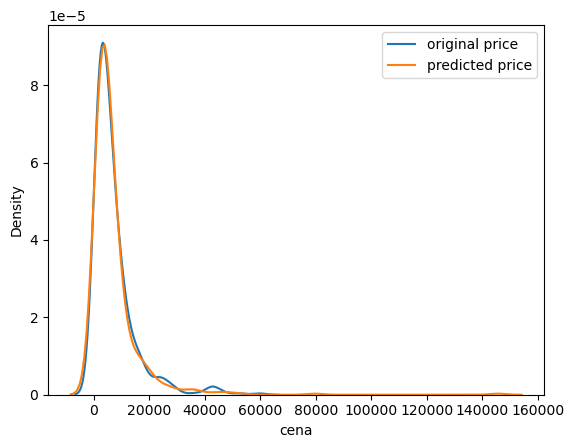

In [88]:
sns.kdeplot(np.exp(y_test_log),label='original price')
sns.kdeplot(np.exp(lre_log.predict(x_test)),label='predicted price')
plt.legend()

### On the plot we can see that the predicted price distribution almost perfectly matches the original prices. The peaks now overlap extremely well and there are no more negative predicted values on the left side, which shows that taking the logarithm of the price significantly improved the model.

In [72]:
print(f"Original model - negative predictions: {(lre.predict(x_test) < 0).sum()} / {len(x_test)}")
print(f"Log model - negative predictions: {(y_pred_original < 0).sum()} / {len(x_test)}")

Original model - negative predictions: 72 / 513
Log model - negative predictions: 0 / 513


#### We can see that the second model has no negative predictions, which represents an improvement over the original model.

#### I will standardize the data and use Ridge regression with GridSearchCV to determine the optimal alpha parameter and see if I can achieve an improvement.

In [43]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
x_train_stand=ss.fit_transform(x_train)
x_test_stand=ss.transform(x_test)

In [44]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
rg=Ridge()
parametri=[{'alpha':[0.01,0.05,0.1,0.5,1]}]
gscv=GridSearchCV(rg,parametri,cv=4)

In [45]:
gscv.fit(x_train_stand,y_train_log)

,estimator,Ridge()
,param_grid,"[{'alpha': [0.01, 0.05, ...]}]"
,scoring,None
,n_jobs,None
,refit,True
,cv,4
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,0.01


In [93]:
best_ridge = gscv.best_estimator_
best_ridge.fit(x_train_stand,y_train_log)
print(best_ridge.score(x_train_stand,y_train_log))
print(best_ridge.score(x_test_stand,y_test_log))
print(mse(y_test,np.exp(best_ridge.predict(x_test_stand)))) #mse
print(np.sqrt(mse(y_test,np.exp(best_ridge.predict(x_test_stand))))) #rmse
print(np.mean(np.abs((y_test - np.exp(best_ridge.predict(x_test_stand))) / y_test)) * 100) #mape

0.7915620422928789
0.8155136211523819
22101435.78411098
4701.216415366451
36.288672700526256


#### We can observe a slight decrease in the errors, while the R² score remains approximately the same. Since the optimal alpha is 0.01, we can conclude that Ridge regression did not provide a significant improvement in model performance.

<Axes: ylabel='cena'>

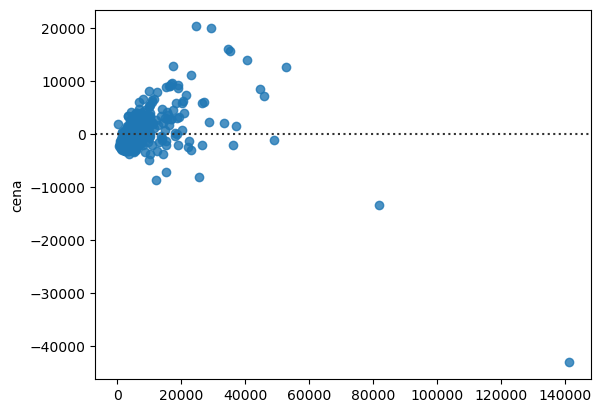

In [82]:
sns.residplot(x=np.exp(best_ridge.predict(x_test_stand)),y=y_test)

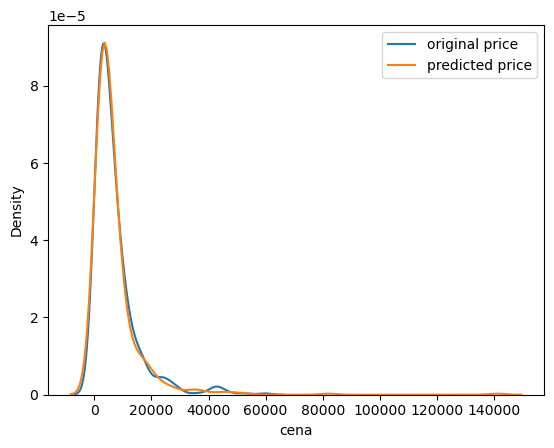

In [89]:
sns.kdeplot(np.exp(y_test_log),label='original price')
sns.kdeplot(np.exp(best_ridge.predict(x_test_stand)),label='predicted price')
plt.legend()

### We can see that the situation is quite similar to the model without Ridge regression, so I will now try to improve the model by removing outliers.

In [50]:
df=df[df['snaga_ks']<300]
x_new=df.drop(['broj_sedista','broj_vrata','snaga_kw','cena'],axis=1)
y_new=np.log(df['cena'])

#### I removed some sports cars because we do not have enough cars with more than 300 horsepower for the model to learn effectively from these data points. I will also remove the data related to the number of seats and doors.

In [94]:
x_new_train,x_new_test,y_new_train,y_new_test=train_test_split(x_new,y_new,test_size=.3,random_state=42)
lre_new=LinearRegression()
lre_new.fit(x_new_train,y_new_train)
print(lre_new.score(x_new_train,y_new_train))
print(lre_new.score(x_new_test,y_new_test))
print(np.sqrt(mse(np.exp(y_new_test),np.exp(lre_new.predict(x_new_test)))))
print(np.mean(np.abs((np.exp(y_new_test) - np.exp(lre_new.predict(x_new_test))) / np.exp(y_new_test))) * 100) #mape

0.7933703518809389
0.7875225187754327
2666.6836510828775
39.10596740304776


#### We can see a decrease in R², but also a decrease in the mean squared error, which represents a trade-off between the two metrics. We also observe a deterioration in the MAPE metric.

In [55]:
import matplotlib.pyplot as plt

<Axes: ylabel='cena'>

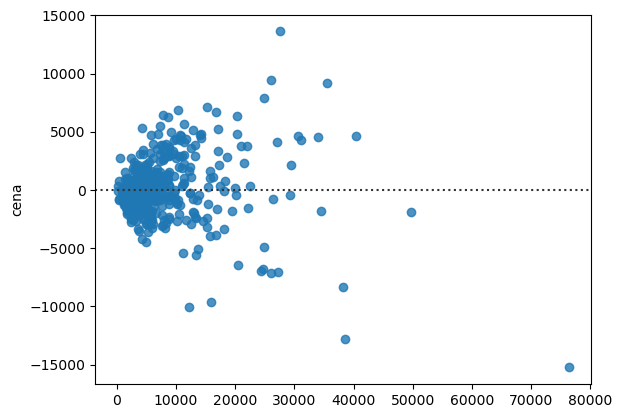

In [86]:
sns.residplot(x=np.exp(lre_new.predict(x_new_test)),y=np.exp(y_new_test))

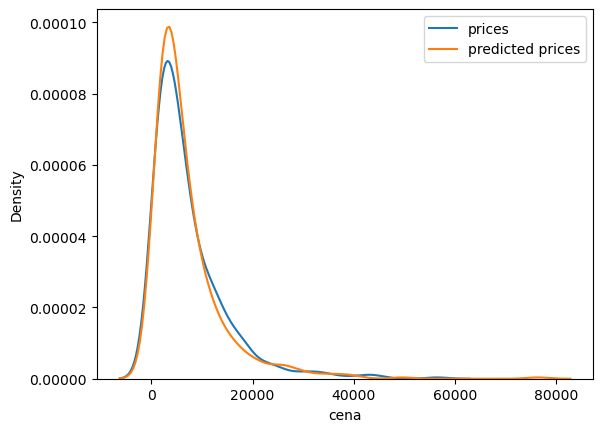

In [84]:
sns.kdeplot(np.exp(y_new_test), label='prices')
sns.kdeplot(np.exp(lre_new.predict(x_new_test)), label='predicted prices')

plt.legend()

plt.show()

#### The fit between the graphs is weaker, and the residuals increase as the price increases.

## Conclusion

The final model is `lre_log` a linear regression model using the log-transformed price as the target variable, without additional filtering by engine power. It achieves R²≈0.81 and MAPE≈36% on the test set.

The log transformation resolved the heteroscedasticity and negative predictions present in the baseline model (MAPE dropped from ~99% to ~36%). Ridge regression did not provide an improvement (optimal alpha≈0), and removing high-power cars reduced RMSE but worsened MAPE showing that a single metric is not sufficient for drawing conclusions.

The model is less reliable for rare, high-performance vehicles, due to an insufficient number of such samples in the dataset. Further work could include collecting more data for that segment, adding additional features (equipment, condition), and experimenting with polynomial regression.